# Idiom Signal Impact and Architecture Analysis

This notebook evaluates the integration of the idiom signal (M) into the ranking pipeline. Theoretically, to make architectural decisions (such as choosing the embedding dimension or projection method), we must use a clean, noiseless signal (Oracle). Using a noisy signal (Predicted) might cause the model to ignore it, obscuring the true architectural differences. Therefore, we use the Predicted signal only to quantify our current pipeline's performance gap, and rely exclusively on the Oracle signal for architectural tuning.

In [9]:
import json
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns
from pathlib import Path

plt.style.use('default')
sns.set_theme(style="white", palette="muted")
plt.rcParams['figure.dpi'] = 300

def load_summary(path_str):
    path = Path(path_str)
    if path.exists():
        with open(path, 'r') as f:
            return json.load(f)
    return None

paths = {
    'Predicted Linear': 'm_dim_ablation_linear/output/summary.json',
    'Predicted PCA': 'm_dim_ablation_pca/output/summary.json',
    'Oracle Linear': 'oracle_ablation_linear/output/summary.json',
    'Oracle PCA': 'oracle_ablation_pca/output/summary.json'
}

data = {}
for name, path in paths.items():
    summary = load_summary(path)
    if summary:
        data[name] = summary['aggregate']

print(f"Loaded {len(data)} ablation families.")

Loaded 4 ablation families.


## Evaluating the Impact of the Idiom Signal

We establish whether integrating the idiom signal improves ranking performance. By comparing the baseline (No M) against both the baseline model (Predicted M) and the Oracle M (ground truth labels), we can quantify both the realistic gains we have now and the theoretical maximum potential we are aiming for.

,Configuration,Dev nDCG,Test nDCG,XEval nDCG
0,No Idiom Signal (m=0),80.57,78.63,70.92
1,Baseline Model (Predicted M),82.89,80.21,72.45
2,Oracle M,87.10,81.31,81.92


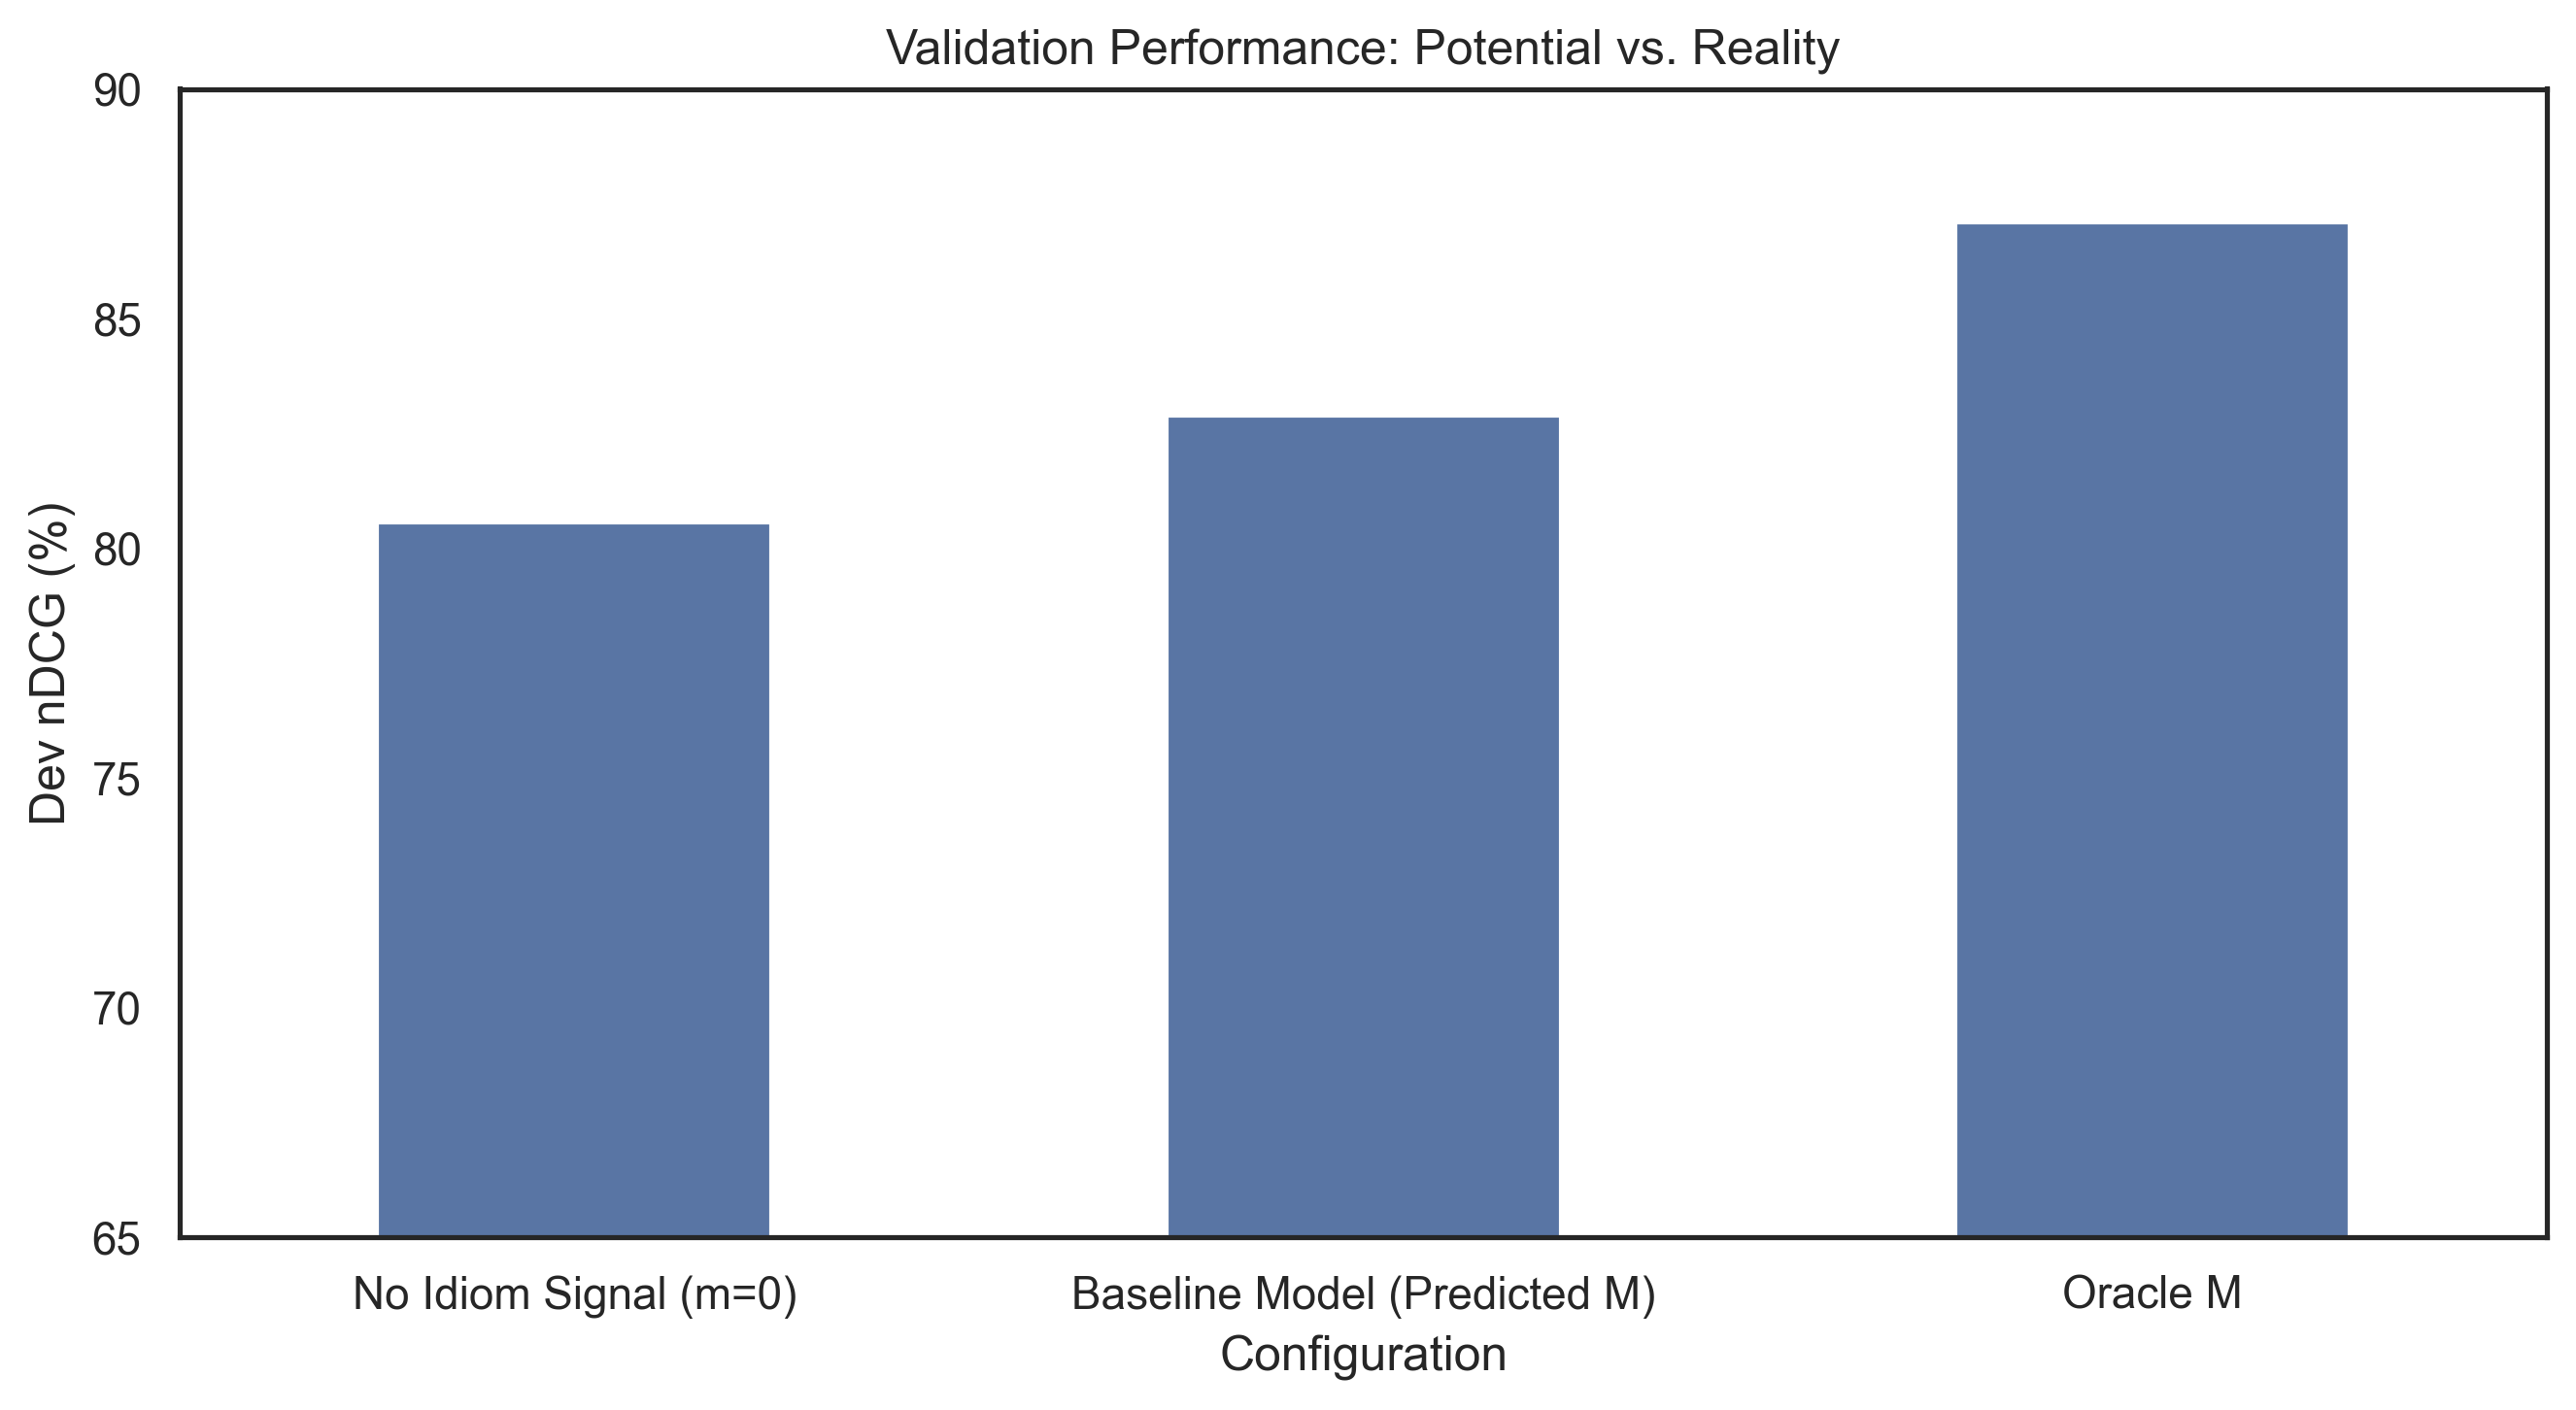

In [10]:
rows = []
for name in ['Predicted Linear', 'Oracle Linear']:
    if name not in data: continue
    
    agg = data[name]
    m0_run = next((r for r in agg if r['m_dim'] == 0), None)
    best_run = max([r for r in agg if r['m_dim'] > 0], key=lambda x: x['best_dev']['ndcg'])
    
    if len(rows) == 0 and m0_run:
        rows.append({
            'Configuration': 'No Idiom Signal (m=0)',
            'Dev nDCG': m0_run['best_dev']['ndcg'] * 100,
            'Test nDCG': m0_run['test']['ndcg'] * 100,
            'XEval nDCG': m0_run['xeval']['ndcg'] * 100
        })
    
    signal_type = 'Baseline Model (Predicted M)' if 'Predicted' in name else 'Oracle M'
    rows.append({
        'Configuration': f"{signal_type}",
        'Dev nDCG': best_run['best_dev']['ndcg'] * 100,
        'Test nDCG': best_run['test']['ndcg'] * 100,
        'XEval nDCG': best_run['xeval']['ndcg'] * 100
    })

df_impact = pd.DataFrame(rows)
display(df_impact.round(2))

plt.figure(figsize=(9, 5))
sns.barplot(data=df_impact, x='Configuration', y='Dev nDCG', color='#4C72B0', width=0.5)
plt.ylim(65, 90)
plt.title('Validation Performance: Potential vs. Reality')
plt.ylabel('Dev nDCG (%)')
plt.tight_layout()
plt.show()

## Determining Optimal Embedding Capacity

To isolate the architectural impact of the capacity dimension (m_dim), we *exclusively* use the Oracle M signal. If we used the noisy predicted signal here, the model's tendency to regularize against the noise could mislead us into picking an artificially low dimension. By using the pure signal, we can observe the true representational capacity required.

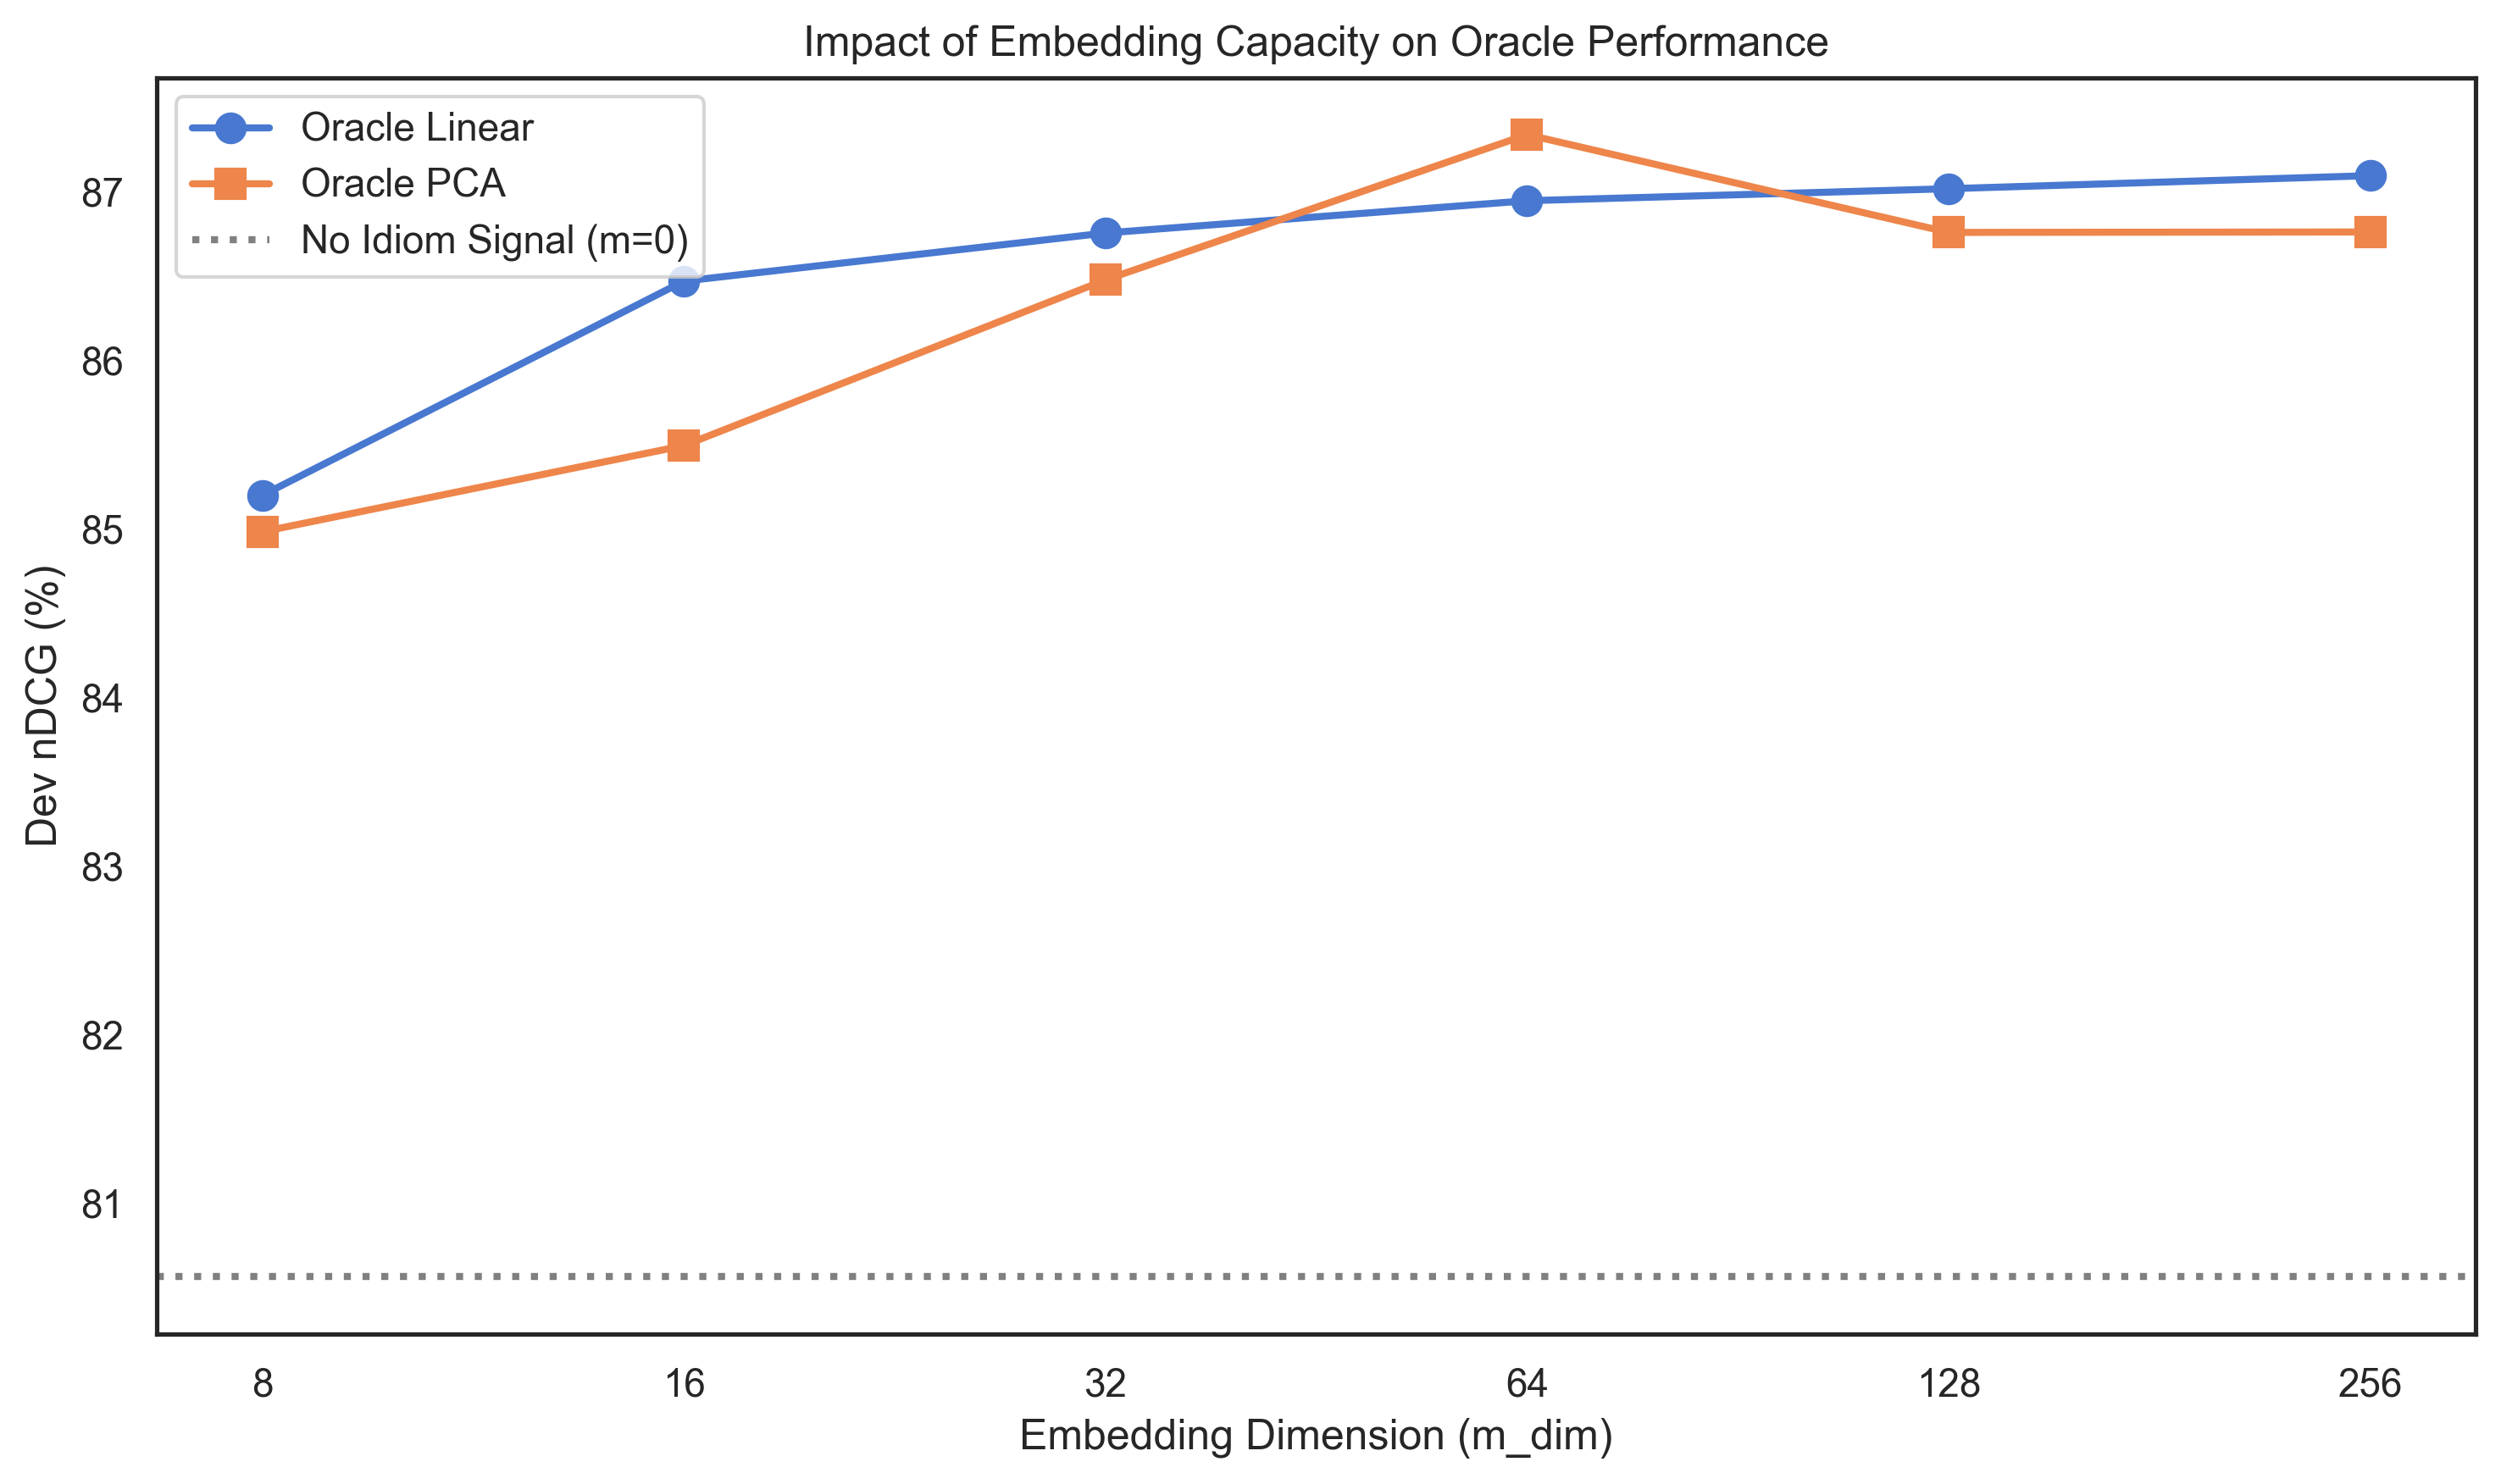

In [11]:
plt.figure(figsize=(10, 6))

# Only plot Oracle families
oracle_families = {k: v for k, v in data.items() if 'Oracle' in k}

for name, agg in oracle_families.items():
    dims = [r['m_dim'] for r in agg if r['m_dim'] > 0]
    scores = [r['best_dev']['ndcg'] * 100 for r in agg if r['m_dim'] > 0]
    
    marker = 'o' if 'Linear' in name else 's'
    plt.plot(dims, scores, marker=marker, linestyle='-', label=name, linewidth=2, markersize=8)

baseline_agg = data.get('Oracle Linear')
if baseline_agg:
    baseline_ndcg = next((r['best_dev']['ndcg'] * 100 for r in baseline_agg if r['m_dim'] == 0), None)
    if baseline_ndcg:
        plt.axhline(y=baseline_ndcg, color='gray', linestyle=':', label='No Idiom Signal (m=0)', linewidth=2)

plt.xscale('log', base=2)
plt.xticks([8, 16, 32, 64, 128, 256], [8, 16, 32, 64, 128, 256])
plt.xlabel('Embedding Dimension (m_dim)')
plt.ylabel('Dev nDCG (%)')
plt.title('Impact of Embedding Capacity on Oracle Performance')
plt.legend()
plt.tight_layout()
plt.show()

## Query Projection Architecture (PCA vs Linear)

Similarly, to judge the architectural merit of PCA vs. Linear projection, we must supply the model with a perfect Oracle signal. This ensures that any performance difference is strictly due to the projection method's ability to fuse effectively with a strong signal, rather than an artifact of signal noise.

,Projection Type,Dev nDCG,Dimension
0,Linear,86.95,64
1,PCA,87.34,64


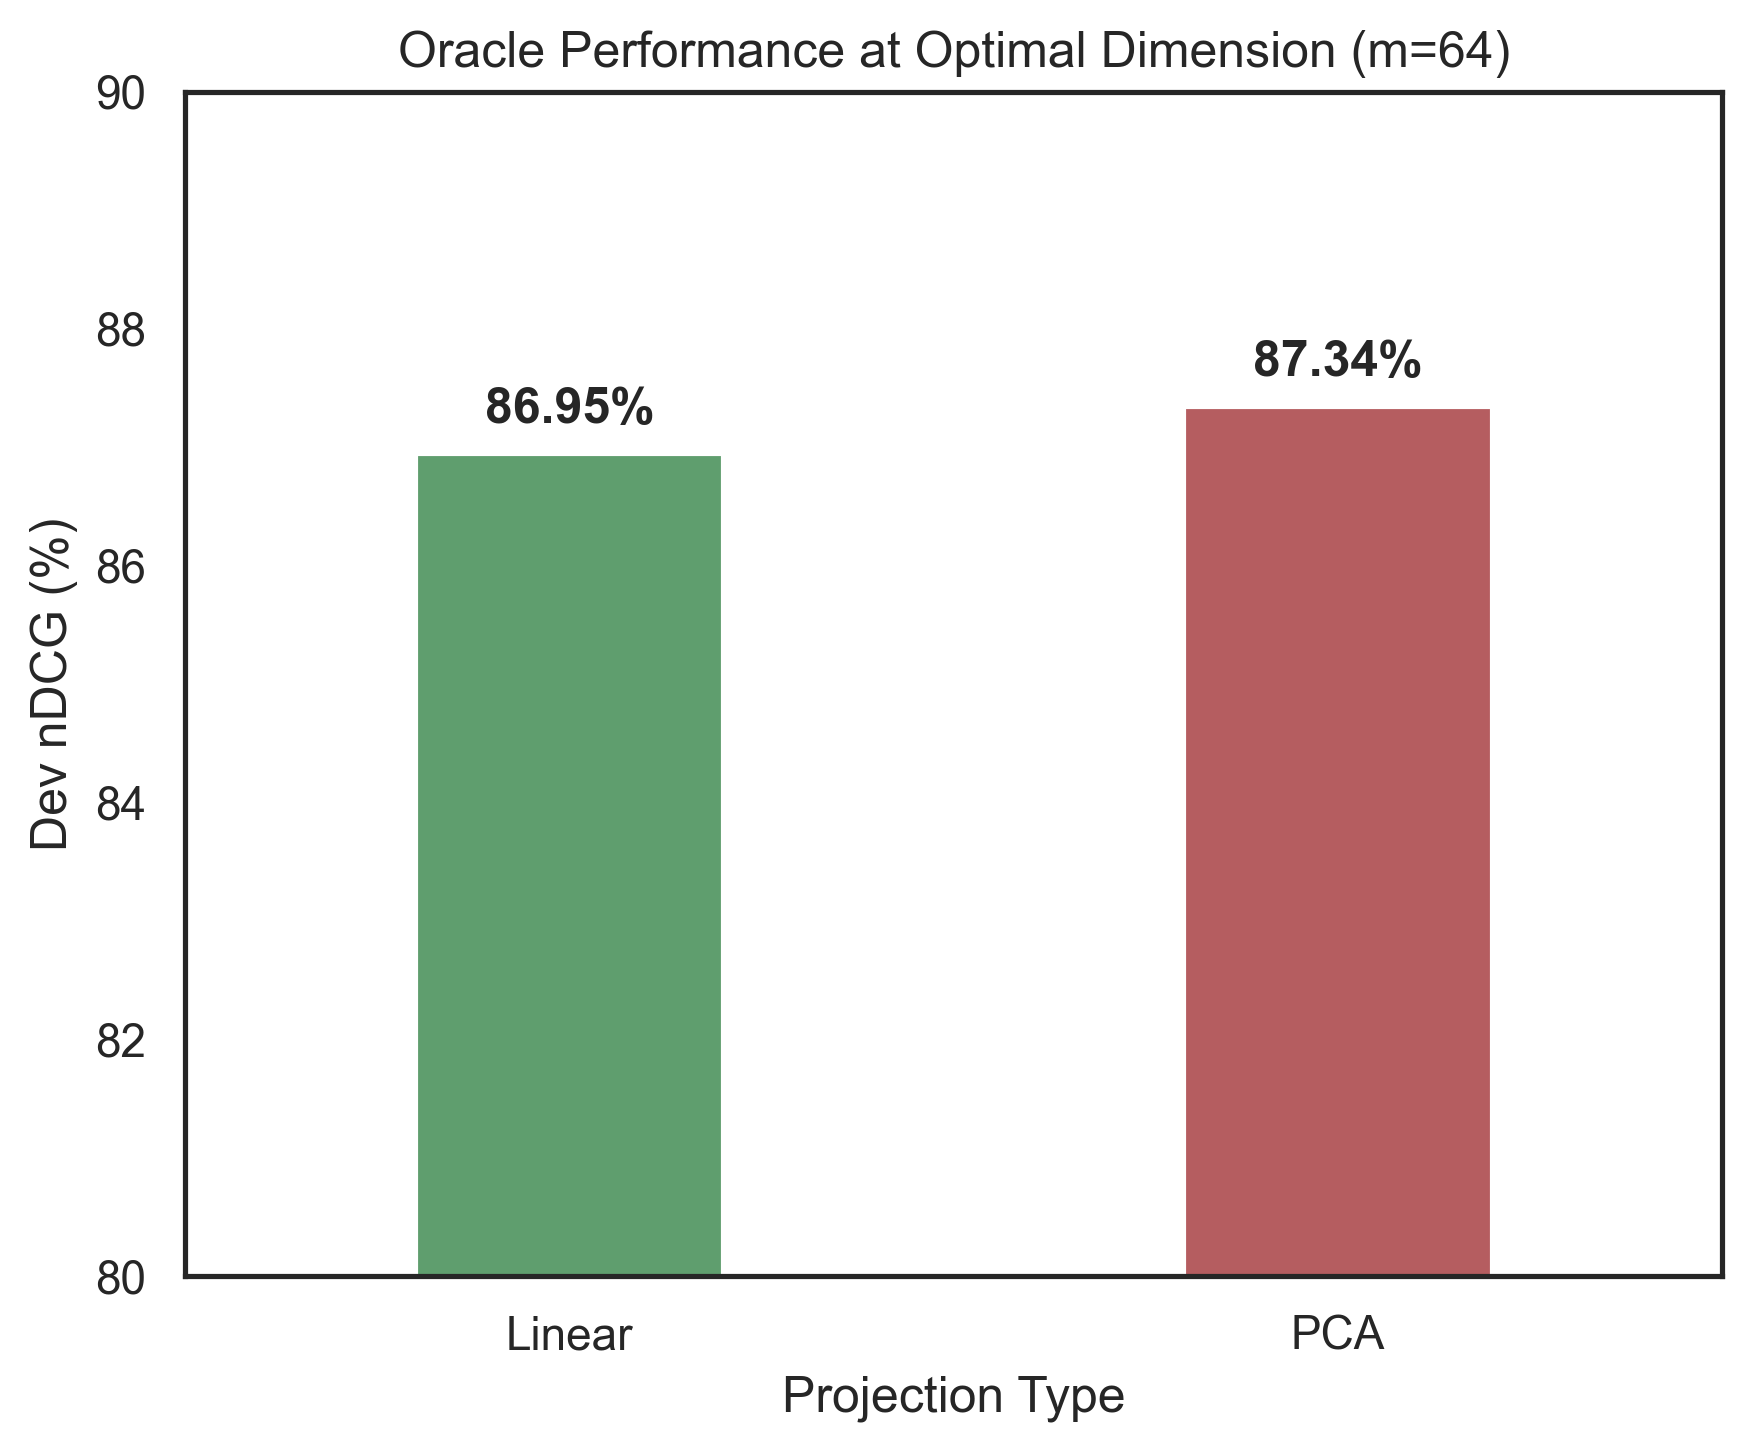

In [12]:
# Compare PCA vs Linear at a specifically chosen optimal dimension (e.g., m=64)
CHOSEN_M_DIM = 64

pca_rows = []
oracle_families = {k: v for k, v in data.items() if 'Oracle' in k}

for name, agg in oracle_families.items():
    run = next((r for r in agg if r['m_dim'] == CHOSEN_M_DIM), None)
    if run:
        pca_rows.append({
            'Projection Type': name.split()[1],
            'Dev nDCG': run['best_dev']['ndcg'] * 100,
            'Dimension': run['m_dim']
        })

df_pca = pd.DataFrame(pca_rows)
display(df_pca.round(2))

plt.figure(figsize=(6, 5))
ax = sns.barplot(data=df_pca, x='Projection Type', y='Dev nDCG', hue='Projection Type', legend=False, palette=['#55A868', '#C44E52'], width=0.4)

# Add accuracy labels on top of the bars
for p in ax.patches:
    ax.annotate(f'{p.get_height():.2f}%',
                (p.get_x() + p.get_width() / 2., p.get_height()),
                ha='center', va='bottom',
                xytext=(0, 5),
                textcoords='offset points',
                fontweight='bold')

plt.ylim(80, 90)
plt.title(f'Oracle Performance at Optimal Dimension (m={CHOSEN_M_DIM})')
plt.ylabel('Dev nDCG (%)')
plt.tight_layout()
plt.show()